# Machine Learning Assignment



In [ ]:
#Uploading Laibraris
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

In [ ]:
# Uploading Data File

file_path = 'student_performance(in).csv'
df = pd.read_csv(file_path)
print(f"Shape: {df.shape}")
df.head()

Shape: (1200, 13)


,student_id,prev_gpa,attendance_pct,study_hours_week,sleep_hours,quiz_avg_20,assignments_submitted,screen_time_hours,commute_minutes,part_time_work_hours,family_size,lms_minutes_month,passed
0,S20000,3.77,41.9,11.0,5.7,12.4,7,4.1,21,0,5,1127,1
1,S20001,3.71,79.6,9.7,5.0,12.5,8,4.6,57,1,7,617,1
2,S20002,3.30,83.1,2.9,6.3,7.6,4,2.9,53,11,7,1783,0
3,S20003,3.33,63.5,17.1,8.4,9.6,9,7.7,6,0,2,1462,1
4,S20004,3.62,81.5,6.9,4.5,10.6,7,1.6,17,0,9,1595,0


In [ ]:
# split data
X = df.drop(['passed'] , axis='columns')
y = df['passed']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

  max_depth  Training Accuracy  Validation Accuracy
0         1           0.731250             0.708333
1         2           0.754167             0.741667
2         3           0.822917             0.800000
3         5           0.883333             0.787500
4        10           0.978125             0.770833
5      None           1.000000             0.733333


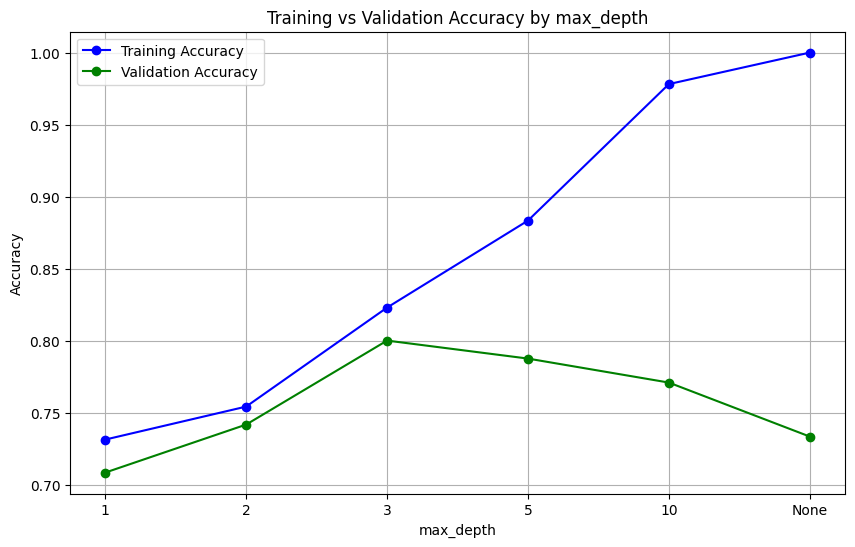

In [ ]:
from sklearn.metrics import accuracy_score
#Train a Decision Tree Classifier using the following values of max_depth
depth_values = [1, 2, 3, 5, 10, None]
# two list to caluclate train and val accuracies
train_accuracies = []
val_accuracies = []

# Drop non-numeric identifier columns like student_id before training
X_train_clean = X_train.drop(columns=['student_id'], errors='ignore')
X_test_clean = X_test.drop(columns=['student_id'], errors='ignore')

# train the modle and calculate the accuracies for every modle
for depth in depth_values:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train_clean, y_train)

    train_acc = accuracy_score(y_train, dt.predict(X_train_clean))
    val_acc = accuracy_score(y_test, dt.predict(X_test_clean))

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

# Show result (Table)
results_df = pd.DataFrame({
    'max_depth': [str(d) for d in depth_values],
    'Training Accuracy': train_accuracies,
    'Validation Accuracy': val_accuracies
    })

print(results_df)

# draw plot (Graph)
plt.figure(figsize=(10, 6))
plt.plot(results_df['max_depth'], train_accuracies, marker='o', label='Training Accuracy', color='blue')
plt.plot(results_df['max_depth'], val_accuracies, marker='o', label='Validation Accuracy', color='green')

plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy by max_depth')
plt.legend()
plt.grid(True)
plt.show()

# Which model appears to be underfitting? Explain why.
The model with max depth = 1, because it gives the lowest value in training accuracy and validation accuracy.
#Which model appears to be overfitting? Explain why.
The model with max depth = None or 10, because it gives a high value in training accuracy that is almost close to 1, but in the validation accuracy the value is low, so that means the model memorized the values and didn't learn anything.
#Which value of max_depth gives the best balance between training and validation performance?
The best max depth = 3 because it gives a balance between validation accuracy and training accuracy, and at the same time it gives the highest value in the validation accuracy.


In [ ]:
param_grid = {
    "max_depth": [2, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_model = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)


grid_search.fit(X_train_clean, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Hyperparameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best Cross-Validation Accuracy: 0.8083333333333333


#Why is cross-validation useful when choosing hyperparameters?
Cross-validation is useful because it splits the data into multiple folds, where each fold acts as both training and testing data iteratively. This ensures that the hyperparameters are chosen based on robust evaluation across different subsets, rather than just a lucky single split.

In [ ]:
best_dt_params = grid_search.best_params_

models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(random_state=42))
    ]),
    'Decision Tree': DecisionTreeClassifier(**best_dt_params, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

results_list = []

for name, model in models.items():
    # Fix: Use X_train_clean instead of X_train to exclude non-numeric 'student_id'
    cv_results = cross_validate(
        model, X_train_clean, y_train,
        cv=5, scoring="accuracy",
        return_train_score=True
    )

    mean_train = cv_results['train_score'].mean()
    mean_cv = cv_results['test_score'].mean()

    results_list.append({
        'Model': name,
        'Mean Training Accuracy': mean_train,
        'Mean Cross-Validation Accuracy': mean_cv
    })

results_task3 = pd.DataFrame(results_list)
display(results_task3)

,Model,Mean Training Accuracy,Mean Cross-Validation Accuracy
0,Logistic Regression,0.817448,0.812500
1,Decision Tree,0.871875,0.808333
2,Random Forest,1.000000,0.836458


#Which model would you select as your final model?
Random Forest
#Why did you select it?
Because it achieved the highest value in Mean Cross-Validation Accuracy compared to the other models, indicating better generalization on unseen data.
#Did any model show signs of overfitting or underfitting?
Yes, Random Forest showed signs of overfitting because there is a noticeable difference (gap) between its training accuracy and cross-validation accuracy.

In [ ]:
baseline_model = RandomForestClassifier(random_state=42)
base_cv = cross_validate(baseline_model, X_train_clean, y_train, cv=5, scoring="accuracy")
before_acc = base_cv['test_score'].mean()

# (Improved Model)
improved_model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
imp_cv = cross_validate(improved_model, X_train_clean, y_train, cv=5, scoring="accuracy")
after_acc = imp_cv['test_score'].mean()

# compareing table
results_task4 = pd.DataFrame({
    'Performance Measure': ['Mean Cross-Validation Accuracy'],
    'Before Improvement': [before_acc],
    'After Improvement': [after_acc]
})
display(results_task4)

,Performance Measure,Before Improvement,After Improvement
0,Mean Cross-Validation Accuracy,0.836458,0.836458


#Did the model improve?
No, the model did not improve in terms of mean cross-validation accuracy.
#What change did you make?
We applied hyperparameter tuning by restricting the maximum depth of the trees (max_depth=6) and increasing the number of trees (n_estimators=200) in the Random Forest model.
#Why do you think this change helped or did not help?
Restricting max_depth to 6 likely made the individual trees too simple (constrained), preventing them from capturing deeper, complex interactions between features in the dataset, which slightly reduced the model's predictive capacity despite increasing the number of trees (n_estimators=200)